<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/notebooks/08_fuzzy_sets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 8 · Fuzzy Sets & Their Algebra

*Neural Network Lab — lesson 8 of 8 · about 30 minutes*

### 🎯 Learning objectives
By the end of this lesson you will be able to:

1. represent vague concepts as fuzzy sets with membership grades in $[0, 1]$;
2. compute complement, union, intersection and difference of fuzzy sets;
3. verify which laws of classical set algebra still hold for fuzzy sets — and which two famously fail;
4. connect fuzzy membership to the graded outputs of sigmoid neurons.

**Prerequisites:** basic set theory (union, intersection, complement).

In [1]:
# ── Setup: runs locally and on Google Colab ──────────────────────────────
try:
    import nnlab
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "git+https://github.com/anupbagale/Neural_Network_lab"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## 1 · From crisp to fuzzy

A classical set draws a sharp line: 24 °C is either “warm” or not. Zadeh (1965) proposed letting
every element belong to a set **to a degree** $\mu_A(x) \in [0, 1]$. Fuzzy sets are the foundation of
fuzzy logic and fuzzy control, and the idea of graded truth is close in spirit to the
sigmoid neurons of Lesson 2, whose outputs are also graded rather than all-or-nothing.

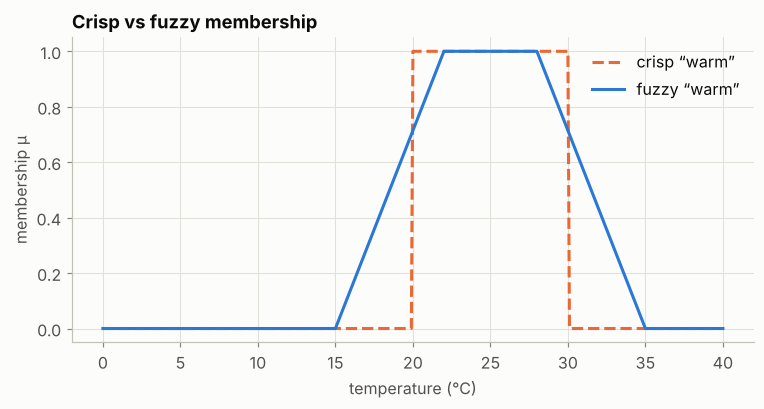

In [2]:
temps = np.linspace(0, 40, 401)
crisp_warm = ((temps >= 20) & (temps <= 30)).astype(float)
fuzzy_warm = np.clip(np.minimum((temps - 15) / 7, (35 - temps) / 7), 0, 1)   # trapezoid 15–22–28–35

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(temps, crisp_warm, color=PALETTE[1], ls="--", label="crisp “warm”")
ax.plot(temps, fuzzy_warm, color=PALETTE[0], label="fuzzy “warm”")
ax.set(xlabel="temperature (°C)", ylabel="membership μ", title="Crisp vs fuzzy membership")
ax.legend()
plt.show()

## 2 · The standard operations

| operation | definition |
|---|---|
| complement | $\mu_{\bar A}(x) = 1 - \mu_A(x)$ |
| union | $\mu_{A \cup B}(x) = \max\big(\mu_A(x), \mu_B(x)\big)$ |
| intersection | $\mu_{A \cap B}(x) = \min\big(\mu_A(x), \mu_B(x)\big)$ |
| difference | $\mu_{A - B}(x) = \min\big(\mu_A(x), 1 - \mu_B(x)\big)$ |

We use the two sets from the original lab on the universe $X = \{1, 2, 3, 4, 5\}$.
`nnlab.fuzzy.FuzzySet` overloads `~`, `|`, `&` and `-` so the code reads like the maths.

In [3]:
from nnlab.fuzzy import FuzzySet, check_properties

X = [1, 2, 3, 4, 5]
A = FuzzySet(X, [0, 1, 0.5, 0.3, 0.2], name="A")
B = FuzzySet(X, [0, 0.5, 0.7, 0.2, 0.4], name="B")

for s in [A, B, ~A, ~B, A | B, A & B, A - B, B - A]:
    print(s)

A = {0/1, 1/2, 0.5/3, 0.3/4, 0.2/5}
B = {0/1, 0.5/2, 0.7/3, 0.2/4, 0.4/5}
¬A = {1/1, 0/2, 0.5/3, 0.7/4, 0.8/5}
¬B = {1/1, 0.5/2, 0.3/3, 0.8/4, 0.6/5}
(A ∪ B) = {0/1, 1/2, 0.7/3, 0.3/4, 0.4/5}
(A ∩ B) = {0/1, 0.5/2, 0.5/3, 0.2/4, 0.2/5}
(A − B) = {0/1, 0.5/2, 0.3/3, 0.3/4, 0.2/5}
(B − A) = {0/1, 0/2, 0.5/3, 0.2/4, 0.4/5}


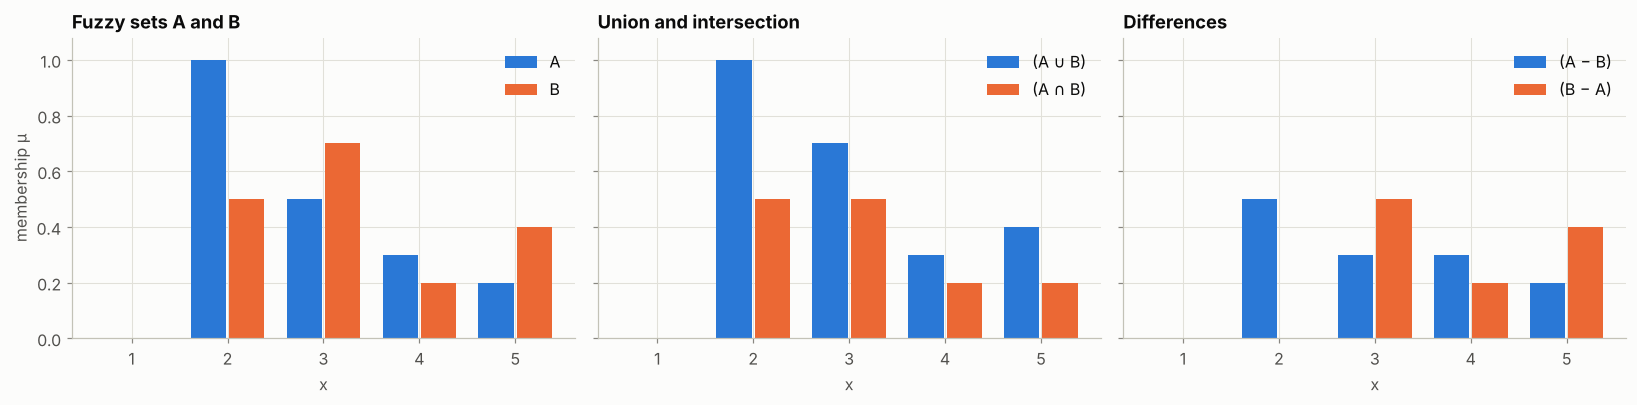

In [4]:
def bars(ax, sets, title):
    width = 0.8 / len(sets)
    for i, (s, color) in enumerate(zip(sets, PALETTE)):
        ax.bar(np.array(X) + (i - (len(sets) - 1) / 2) * width, s.membership, width=width * 0.92,
               color=color, label=s.name)
    ax.set(xticks=X, ylim=(0, 1.08), title=title, xlabel="x")
    ax.legend(loc="upper right")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
bars(axes[0], [A, B], "Fuzzy sets A and B")
bars(axes[1], [A | B, A & B], "Union and intersection")
bars(axes[2], [A - B, B - A], "Differences")
axes[0].set_ylabel("membership μ")
fig.tight_layout()
plt.show()

> **Note for readers of the original notebook.** A few labels in the first version were swapped:
> the check printed as “associative” actually tested *commutativity* (and vice versa),
> $\min(\mu_B, 1 - \mu_A)$ was labelled $A - V$ although it is $B - A$, and the De Morgan check printed
> $\bar A \cap \bar B$ under the name “$(A \cap V)$ complement”. The table below uses the correct names.

## 3 · Which laws survive?

In [5]:
C = FuzzySet(X, [0.4, 0.2, 0.7, 1, 0.5], name="C")
for law, holds in check_properties(A, B, C).items():
    print(f"{'✔' if holds else '✘'}  {law}")

✔  commutative (∪)
✔  commutative (∩)
✔  associative (∪)
✔  associative (∩)
✔  distributive (∪ over ∩)
✔  distributive (∩ over ∪)
✔  De Morgan ¬(A ∪ B) = ¬A ∩ ¬B
✔  De Morgan ¬(A ∩ B) = ¬A ∪ ¬B
✔  involution ¬¬A = A
✘  excluded middle A ∪ ¬A = X
✘  non-contradiction A ∩ ¬A = ∅


Commutativity, associativity, distributivity, involution and both De Morgan laws carry over
unchanged. Two laws do **not**:

* **Excluded middle** $A \cup \bar A = X$ fails: $\mu_{A \cup \bar A}(3) = \max(0.5, 0.5) = 0.5 \ne 1$.
* **Non-contradiction** $A \cap \bar A = \varnothing$ fails: $\mu_{A \cap \bar A}(3) = 0.5 \ne 0$.

This is not a defect — it is the point. Something can be *partly* warm and *partly* not warm at the
same time.

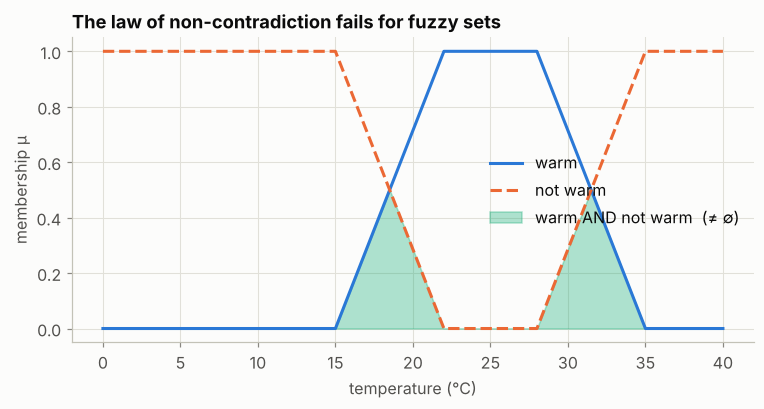

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
not_warm = 1 - fuzzy_warm
ax.plot(temps, fuzzy_warm, color=PALETTE[0], label="warm")
ax.plot(temps, not_warm, color=PALETTE[1], ls="--", label="not warm")
ax.fill_between(temps, np.minimum(fuzzy_warm, not_warm), color=PALETTE[2], alpha=0.35,
                label="warm AND not warm  (≠ ∅)")
ax.set(xlabel="temperature (°C)", ylabel="membership μ", title="The law of non-contradiction fails for fuzzy sets")
ax.legend(loc="center right")
plt.show()

## 4 · Try it yourself

1. Write membership functions for “cold” and “hot” on the temperature axis, then plot
   “warm OR hot” and “NOT cold AND NOT hot”.
2. Zadeh's max/min are not the only choices. The *algebraic* operators use
   $\mu_{A\cap B} = \mu_A \mu_B$ and $\mu_{A\cup B} = \mu_A + \mu_B - \mu_A\mu_B$. Which properties in
   the table still hold for these operators?

**❓ Exercise 2 answer**

<details><summary>Show answer</summary>

Commutativity, associativity and De Morgan's laws still hold; **idempotence** ($A \cap A = A$) and **distributivity** fail. You can check this numerically by writing two small functions and comparing memberships with `np.allclose`.

</details>

## 📌 Summary

- A fuzzy set assigns each element a membership grade between 0 and 1.
- Complement, union, intersection and difference are 1 − μ, max, min and min(μ_A, 1 − μ_B).
- Most classical set laws still hold, but excluded middle and non-contradiction fail.
- Graded membership mirrors the graded outputs of sigmoid neurons.

🎉 **You have finished the lab!** See the [README](../README.md) for ideas on where to go next.

---

#### References
- Zadeh, L. A. (1965). Fuzzy sets. *Information and Control*, 8(3), 338–353.
- Klir, G. J., & Yuan, B. (1995). *Fuzzy Sets and Fuzzy Logic: Theory and Applications*. Prentice Hall.